# Sistema predictivo de retención de clientes

En este notebook preparé un primer recorrido con el dataset Telco Customer Churn. Primero cargué y revisé los datos; después limpié algunas columnas, probé tres modelos e hice una cuenta económica sencilla con supuestos que se pueden cambiar.

La cuenta es sólo una simulación: el archivo no trae información de campañas reales.

## 1. Preparar las librerías

Dejé esta celda para instalar las librerías que usé en el balanceo, XGBoost y la conexión opcional con PostgreSQL. Colab ya trae pandas y scikit-learn.

In [1]:
%pip -q install imbalanced-learn xgboost sqlalchemy psycopg2-binary



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
)
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from xgboost import XGBClassifier

# Fijé una semilla para poder repetir la separación aleatoria.
SEMILLA = 42


## 2. Cargar y revisar el dataset

Primero usé el mismo archivo indicado en el material de clase. Lo dejé fuera de GitHub porque se puede descargar desde este enlace cada vez que corro el notebook.

In [3]:
URL_DATASET = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Leí el archivo con pandas directamente desde el enlace.
df_original = pd.read_csv(URL_DATASET)

print("Filas y columnas:", df_original.shape)
display(df_original.head())
print("\nColumnas:")
print(df_original.columns.tolist())


Filas y columnas: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Columnas:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [4]:
# Comprobé que estuvieran las columnas principales antes de seguir.
columnas_necesarias = ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
faltantes = [columna for columna in columnas_necesarias if columna not in df_original.columns]

if faltantes:
    raise ValueError(f"Faltan columnas que necesito: {faltantes}")

print("Valores vacíos por columna:")
display(df_original.isna().sum().sort_values(ascending=False).head(10))


Valores vacíos por columna:


customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

## 3. Limpieza básica y primera exploración

Encontré que `TotalCharges` podía llegar como texto y con espacios vacíos, así que lo convertí a número. A los clientes nuevos, que tenían cero meses y el cargo total vacío, les asigné 0. Los otros valores faltantes los completé durante el modelado.

In [5]:
df = df_original.copy()

# Cambié el tipo de esta columna porque como texto no servía para los cálculos.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Tomé como clientes nuevos las filas sin TotalCharges y con tenure igual a cero.
clientes_nuevos = (df["tenure"] == 0) & (df["TotalCharges"].isna())
df.loc[clientes_nuevos, "TotalCharges"] = 0

# Convertí la respuesta Yes/No a 1/0 para que el modelo pudiera aprenderla.
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Quité las filas sin identificador o sin respuesta porque no servían para entrenar.
df = df.dropna(subset=["customerID", "Churn"]).copy()

print("Filas después de la limpieza:", len(df))
print("Proporción de bajas:")
display(df["Churn"].value_counts(normalize=True).rename("proporción"))


Filas después de la limpieza: 7043
Proporción de bajas:


Churn
0    0.73463
1    0.26537
Name: proporción, dtype: float64

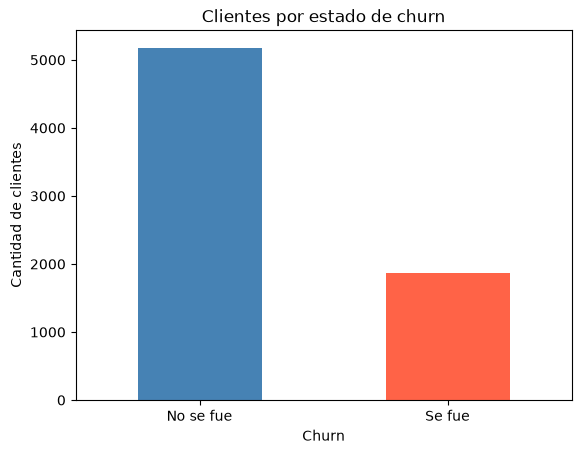

In [6]:
# Usé este gráfico para ver si la variable objetivo estaba desbalanceada.
df["Churn"].value_counts().sort_index().plot(kind="bar", color=["steelblue", "tomato"])
plt.xticks([0, 1], ["No se fue", "Se fue"], rotation=0)
plt.ylabel("Cantidad de clientes")
plt.title("Clientes por estado de churn")
plt.show()


## 4. Separar los datos y preparar las columnas

Separé una parte para probar los modelos al final. Usé `stratify` para mantener una proporción parecida de bajas en entrenamiento y prueba. Dejé el balanceo dentro del pipeline para que se aplicara sólo al entrenamiento.

In [7]:
# Dejé afuera customerID porque identifica a cada persona, pero no explica por sí solo si se va.
columnas_excluidas = ["Churn", "customerID"]
X = df.drop(columns=columnas_excluidas)
y = df["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y,
)

columnas_numericas = X.select_dtypes(include=["number"]).columns.tolist()
columnas_texto = X.select_dtypes(exclude=["number"]).columns.tolist()

# A las columnas numéricas les completé los vacíos con la mediana y las escalé.
preparar_numeros = Pipeline(steps=[
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

# A las columnas de texto les completé los vacíos con el valor más frecuente y
# convertí sus categorías en columnas numéricas.
preparar_texto = Pipeline(steps=[
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore")),
])

preparar_datos = ColumnTransformer(transformers=[
    ("numeros", preparar_numeros, columnas_numericas),
    ("texto", preparar_texto, columnas_texto),
])

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))


Filas de entrenamiento: 5634
Filas de prueba: 1409


## 5. Entrenar y comparar modelos

Probé tres modelos del proyecto: Regresión Logística, Random Forest y XGBoost. Puse `RandomOverSampler` dentro de cada pipeline para balancear sólo los datos de entrenamiento. También calibré las probabilidades con una validación interna porque después las usé en la cuenta económica.

In [8]:
# Calculé el peso de las bajas para que XGBoost también tuviera en cuenta
# que había menos casos positivos que negativos.
cantidad_no = int((y_train == 0).sum())
cantidad_si = int((y_train == 1).sum())
peso_bajas = cantidad_no / cantidad_si

modelos_base = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=peso_bajas,
        eval_metric="logloss",
        random_state=SEMILLA,
        n_jobs=-1,
    ),
}

modelos_entrenados = {}
resultados = []

for nombre, modelo in modelos_base.items():
    # Ajusté el preprocesamiento y el balanceo dentro de cada partición,
    # así los datos de prueba no pasaron al entrenamiento.
    pipeline = ImbalancedPipeline(steps=[
        ("preparar", preparar_datos),
        ("balancear", RandomOverSampler(random_state=SEMILLA)),
        ("modelo", modelo),
    ])

    modelo_calibrado = CalibratedClassifierCV(
        estimator=pipeline,
        method="sigmoid",
        cv=3,
    )
    modelo_calibrado.fit(X_train, y_train)
    probabilidad = modelo_calibrado.predict_proba(X_test)[:, 1]
    prediccion = (probabilidad >= 0.5).astype(int)

    modelos_entrenados[nombre] = modelo_calibrado
    resultados.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, prediccion),
        "precision": precision_score(y_test, prediccion, zero_division=0),
        "recall": recall_score(y_test, prediccion, zero_division=0),
        "f1": f1_score(y_test, prediccion, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilidad),
        "brier": brier_score_loss(y_test, probabilidad),
    })

tabla_resultados = pd.DataFrame(resultados).sort_values("roc_auc", ascending=False)
display(tabla_resultados.round(3))


,modelo,accuracy,precision,recall,f1,roc_auc,brier
2,XGBoost,0.799,0.632,0.583,0.606,0.842,0.139
0,Regresión Logística,0.802,0.650,0.551,0.596,0.841,0.138
1,Random Forest,0.791,0.653,0.452,0.534,0.828,0.143


## 6. Probar una decisión económica

Tomé como referencia el modelo que tuvo mayor ROC AUC en la prueba. Después usé supuestos editables para estimar un valor esperado por cliente. Son números de ejemplo; el dataset no los trae.

In [9]:
mejor_nombre = tabla_resultados.iloc[0]["modelo"]
mejor_modelo = modelos_entrenados[mejor_nombre]

# Dejé estos supuestos como ejemplo; habría que reemplazarlos por datos reales del negocio.
COSTO_CAMPANIA = 20.0
MESES_ESPERADOS = 6
MARGEN_ESTIMADO = 0.40
EXITO_CAMPANIA = 0.30

probabilidad_baja = mejor_modelo.predict_proba(X_test)[:, 1]
cargo_mensual = df.loc[X_test.index, "MonthlyCharges"].to_numpy()

# Aproximé el beneficio como el margen esperado durante algunos meses.
beneficio_si_se_retiene = cargo_mensual * MESES_ESPERADOS * MARGEN_ESTIMADO
valor_esperado_neto = (
    probabilidad_baja * EXITO_CAMPANIA * beneficio_si_se_retiene
    - COSTO_CAMPANIA
)

# Si el valor esperado dio positivo, la campaña parecía conveniente bajo estos supuestos.
recomendar_campania = valor_esperado_neto > 0

print("Modelo elegido:", mejor_nombre)
print("Clientes de prueba:", len(X_test))
print("Clientes para contactar:", int(recomendar_campania.sum()))
print("Valor esperado neto total estimado: $", round(valor_esperado_neto.sum(), 2))


Modelo elegido: XGBoost
Clientes de prueba: 1409
Clientes para contactar: 445
Valor esperado neto total estimado: $ -8444.1


In [10]:
# Presenté la matriz de confusión económica de forma simple.
# Aclaré que el valor esperado no demuestra que la campaña vaya a funcionar en la realidad.
matriz_decision = pd.DataFrame({
    "resultado_real": y_test.map({0: "No churn", 1: "Churn"}).to_numpy(),
    "recomendar_campania": recomendar_campania,
    "probabilidad_churn": probabilidad_baja,
    "valor_esperado_neto": valor_esperado_neto,
})

resumen_decision = matriz_decision.groupby(
    ["resultado_real", "recomendar_campania"],
    as_index=False,
).agg(
    clientes=("probabilidad_churn", "size"),
    probabilidad_promedio=("probabilidad_churn", "mean"),
    valor_esperado_total=("valor_esperado_neto", "sum"),
)
display(resumen_decision.round(2))


,resultado_real,recomendar_campania,clientes,probabilidad_promedio,valor_esperado_total
0,Churn,False,138,0.31,-1375.67
1,Churn,True,236,0.57,3395.41
2,No churn,False,826,0.11,-12853.58
3,No churn,True,209,0.50,2389.73


## 7. Guardar una tabla para revisar

Dejé preparada una tabla con las predicciones del conjunto de prueba. Al ejecutar esta celda se guarda como `predicciones_para_revision.csv`. No incluye resultados de campañas reales.

In [11]:
predicciones = pd.DataFrame({
    "customer_id": df.loc[X_test.index, "customerID"].to_numpy(),
    "churn_real": y_test.to_numpy(),
    "probabilidad_churn": probabilidad_baja,
    "valor_esperado_neto": valor_esperado_neto,
    "recomendar_campania": recomendar_campania,
})

predicciones.to_csv("predicciones_para_revision.csv", index=False)
print("Se guardó predicciones_para_revision.csv")
display(predicciones.head())


Se guardó predicciones_para_revision.csv


,customer_id,churn_real,probabilidad_churn,valor_esperado_neto,recomendar_campania
0,4376-KFVRS,0,0.017482,-18.564447,False
1,2754-SDJRD,0,0.654348,27.183726,True
2,9917-KWRBE,0,0.064092,-16.384437,False
3,0365-GXEZS,0,0.441474,4.856728,True
4,9385-NXKDA,0,0.017894,-18.935188,False


## 8. Carga opcional en PostgreSQL

Dejé esta parte apagada por defecto. Para probarla, primero hay que ejecutar el SQL del repositorio en una base de práctica y configurar `DATABASE_URL` como variable de entorno en Colab. La celda reemplaza los datos de las dos tablas de este proyecto.

In [12]:
CARGAR_EN_POSTGRES = False

if CARGAR_EN_POSTGRES:
    from sqlalchemy import create_engine, text

    database_url = os.environ.get("DATABASE_URL")
    if not database_url:
        raise ValueError("Falta configurar DATABASE_URL")

    # Dejé los nombres de las columnas iguales a los del script SQL.
    datos_sql = df.rename(columns={
        "customerID": "customer_id",
        "SeniorCitizen": "senior_citizen",
        "PhoneService": "phone_service",
        "MultipleLines": "multiple_lines",
        "InternetService": "internet_service",
        "OnlineSecurity": "online_security",
        "OnlineBackup": "online_backup",
        "DeviceProtection": "device_protection",
        "TechSupport": "tech_support",
        "StreamingTV": "streaming_tv",
        "StreamingMovies": "streaming_movies",
        "Contract": "contract",
        "PaperlessBilling": "paperless_billing",
        "PaymentMethod": "payment_method",
        "MonthlyCharges": "monthly_charges",
        "TotalCharges": "total_charges",
        "Churn": "churn",
    })

    dim_customer = datos_sql[[
        "customer_id", "gender", "senior_citizen", "partner", "dependents"
    ]]
    fact_subscription = datos_sql[[
        "customer_id", "tenure", "phone_service", "multiple_lines",
        "internet_service", "online_security", "online_backup",
        "device_protection", "tech_support", "streaming_tv",
        "streaming_movies", "contract", "paperless_billing",
        "payment_method", "monthly_charges", "total_charges", "churn"
    ]]

    engine = create_engine(database_url)
    with engine.begin() as conexion:
        # Borré primero la tabla que tenía la clave foránea y después la dimensión.
        conexion.execute(text("DELETE FROM fact_subscription"))
        conexion.execute(text("DELETE FROM dim_customer"))
        dim_customer.to_sql("dim_customer", conexion, if_exists="append", index=False)
        fact_subscription.to_sql("fact_subscription", conexion, if_exists="append", index=False)

    print("La carga en PostgreSQL terminó.")
else:
    print("Carga apagada. Para usarla, configura DATABASE_URL y cambia el valor a True.")


Carga apagada. Para usarla, configura DATABASE_URL y cambia el valor a True.
